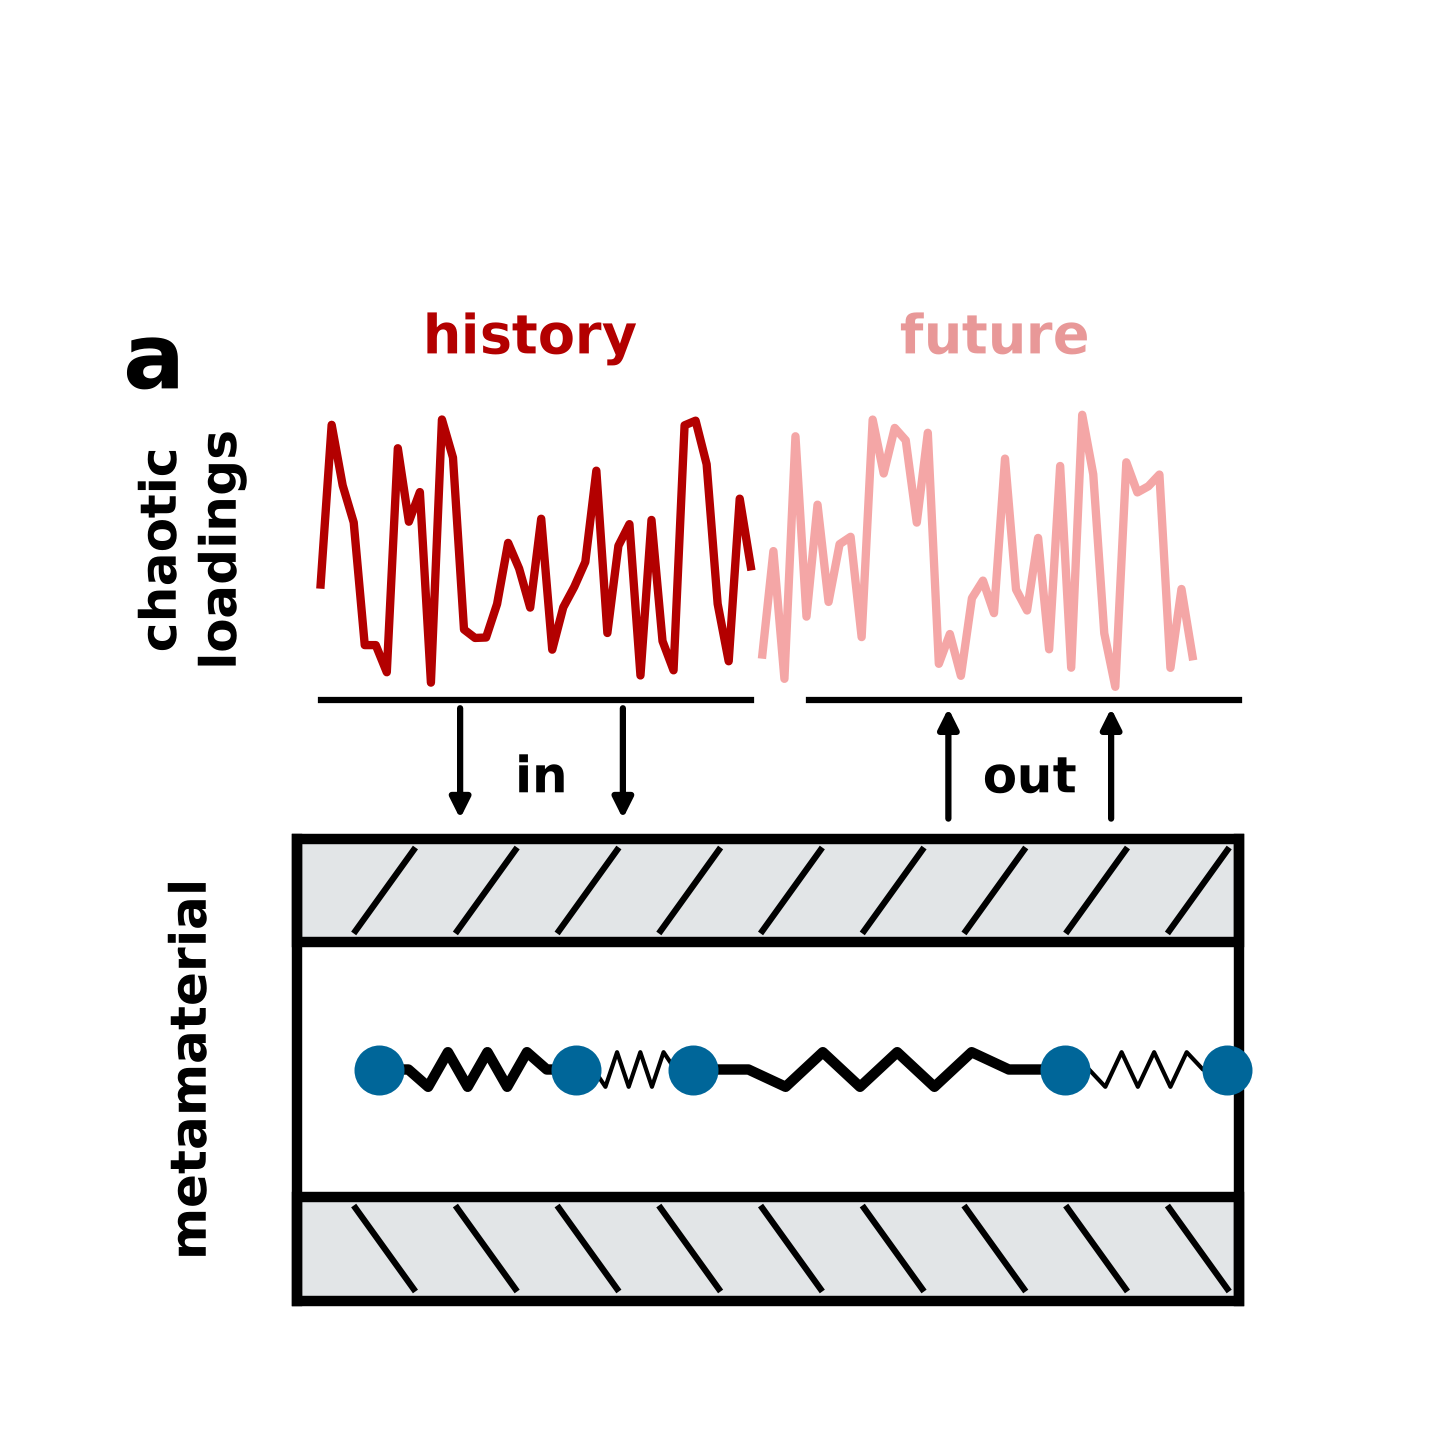

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.1, 1.1)
ax.axis("off")


# Helper function to generate a spring path between two points
def get_spring(p1, p2, nodes=10, width=0.03):
    p1, p2 = np.array(p1), np.array(p2)
    dist = np.linalg.norm(p2 - p1)
    direction = (p2 - p1) / dist
    normal = np.array([-direction[1], direction[0]])

    # Linear lead-in and lead-out
    lead_in = 0.15 * dist
    lead_out = 0.15 * dist
    spring_len = dist - lead_in - lead_out

    t = np.linspace(0, spring_len, nodes)
    offsets = np.sin(np.pi * np.arange(nodes)) * 0 + width * ((-1) ** np.arange(nodes))
    offsets[0] = 0
    offsets[-1] = 0

    pts = [p1, p1 + direction * lead_in]
    for s_t, off in zip(t, offsets):
        pts.append(p1 + direction * (lead_in + s_t) + normal * off)
    pts.append(p2 - direction * lead_out)
    pts.append(p2)
    return np.array(pts)


# 1. Top Signals (History & Future)
np.random.seed(42)
x_hist = np.linspace(0.15, 0.52, 40)
y_hist = 0.65 + np.random.uniform(-0.12, 0.12, len(x_hist))
x_fut = np.linspace(0.53, 0.90, 40)
y_fut = 0.65 + np.random.uniform(-0.12, 0.12, len(x_fut))

ax.plot(x_hist, y_hist, color="#b30000", lw=2)
ax.plot(x_fut, y_fut, color="#f4a6a6", lw=2)
ax.plot([0.15, 0.52], [0.52, 0.52], color="black", lw=1.5)
ax.plot([0.57, 0.94], [0.52, 0.52], color="black", lw=1.5)

ax.text(0.33, 0.82, "history", color="#b30000", fontsize=13, weight="bold", ha="center")
ax.text(0.73, 0.82, "future", color="#e89898", fontsize=13, weight="bold", ha="center")

# 2. Arrows (in / out)
arrow_kw = dict(arrowstyle="-|>", lw=1.5, mutation_scale=10, color="black")
ax.annotate("", xy=(0.27, 0.41), xytext=(0.27, 0.52), arrowprops=arrow_kw)
ax.annotate("", xy=(0.41, 0.41), xytext=(0.41, 0.52), arrowprops=arrow_kw)
ax.text(0.34, 0.44, "in", fontsize=12, weight="bold", ha="center")

ax.annotate("", xy=(0.69, 0.52), xytext=(0.69, 0.41), arrowprops=arrow_kw)
ax.annotate("", xy=(0.83, 0.52), xytext=(0.83, 0.41), arrowprops=arrow_kw)
ax.text(0.76, 0.44, "out", fontsize=12, weight="bold", ha="center")

# 3. Metamaterial Plates
plate_top = patches.Rectangle(
    (0.13, 0.31), 0.81, 0.09, facecolor="#e2e5e7", edgecolor="black", lw=2.5
)
plate_bot = patches.Rectangle(
    (0.13, 0.00), 0.81, 0.09, facecolor="#e2e5e7", edgecolor="black", lw=2.5
)
ax.add_patch(plate_top)
ax.add_patch(plate_bot)

for x_offset in np.linspace(0.18, 0.88, 9):
    ax.plot([x_offset, x_offset + 0.05], [0.32, 0.39], color="black", lw=1.5)
    ax.plot([x_offset, x_offset + 0.05], [0.08, 0.01], color="black", lw=1.5)

# 4. Metamaterial Inner Frame & Nodes
ax.plot([0.13, 0.13], [0.00, 0.40], color="black", lw=2.5)
ax.plot([0.94, 0.94], [0.00, 0.40], color="black", lw=2.5)

node_xs = [0.20, 0.37, 0.47, 0.79, 0.93]
node_y = 0.20
for x in node_xs:
    ax.plot(x, node_y, "o", color="#006699", markersize=11, zorder=5)

# Draw springs between nodes
for i in range(len(node_xs) - 1):
    p_pts = get_spring(
        (node_xs[i], node_y), (node_xs[i + 1], node_y), nodes=8, width=0.015
    )
    lw = 2.5 if i % 2 == 0 else 1.0
    ax.plot(p_pts[:, 0], p_pts[:, 1], color="black", lw=lw, zorder=3)

# 5. Side Labels
ax.text(-0.02, 0.85, "a", fontsize=22, weight="bold", va="top")
ax.text(
    0.04,
    0.65,
    "chaotic\nloadings",
    fontsize=12,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)
ax.text(
    0.04,
    0.20,
    "metamaterial",
    fontsize=12,
    weight="bold",
    rotation=90,
    va="center",
    ha="center",
)

# Save directly as SVG or PNG
# plt.savefig("metamaterial_diagram.svg", bbox_inches="tight")
# plt.savefig("metamaterial_diagram.png", bbox_inches="tight", dpi=300)
plt.show()